# 数値計算演習C：軸対称・非軸対称ポテンシャル中の軌道

**Ryden, *Celestial and Stellar Dynamics*, §7.2–7.3**

Notebook 3のリープフロッグ法を、異なる重力場へ再利用します。加速度関数を差し替えるだけでなく、各モデルで使える保存量と比較の基準を選び直し、数値軌道を検証します。解析的な加速度を使うため、Notebook BのPoisson解は必要ありません。

## 学習目標

1. 加速度関数と初期条件を設定し、第3章の時間積分法を異なる重力場へ再利用できる。
2. ポテンシャルの対称性に応じて保存量を選び、数値軌道の診断に用いることができる。
3. 厳密解が得られない問題で、小振幅近似を近似的な参照解として用い、数値軌道との差を評価できる。
4. 時間刻みと初期振幅を別々に変え、時間積分の誤差と小振幅近似との差を区別できる。
5. 非軸対称系の角運動量の変化を数値誤差と区別し、有限時間の軌道から判断できる範囲を説明できる。


## 実行順序とテキストとの対応

このNotebookは単独で、上から順に実行できます。他のNotebookの実行結果は必要ありません。設定を変更した場合は、カーネルを再起動して全セルを実行してください。

第3章の発展演習です。対応する導出はテキスト付録Cにあり、他の付録を先に学ぶ必要はありません。

| テキストの内容 | Notebook Cの節名 |
| --- | --- |
| 異なる重力場への時間積分法の適用 | 「準備：第3章のリープフロッグ法の再利用」 |
| 軸対称系とエピサイクル運動 | 「軸対称ポテンシャル」「ほぼ円軌道とエピサイクル運動」 |
| 時間刻みと初期振幅の切り分け | 「時間刻みを変えた収束試験」「初期振幅を変えた近似解との比較」 |
| Miyamoto–Nagaiポテンシャル中の軌道 | 「Miyamoto–Nagai軌道」 |
| 非軸対称系の軌道と診断 | 「非軸対称ポテンシャル」 |

## 準備：第3章のリープフロッグ法の再利用

単独実行のため、Notebook 3と同じKDK（kick–drift–kick）形式の積分関数を再掲します。`acc_func(x)`は1点の位置配列を受け取り、同じ次元の加速度配列を返します。返される`x`と`v`の形は`(nstep + 1, ndim)`で、初期状態も含みます。モデルを変えても時間ループは変えません。

以下の重力場は、時間・速度に依存せず、粒子の運動によっても変わらないものとします。2次元・3次元ともCartesian 座標で積分します。円筒座標の半径は、計算後に$R=\sqrt{x^2+y^2}$で求めます。

比エネルギーと比角運動量の$z$成分は
$$
E=\frac12|\boldsymbol v|^2+\Phi(\boldsymbol x),\qquad L_z=xv_y-yv_x
$$
です。$E$は時間に依存しないポテンシャルで保存し、$L_z$はさらに軸対称であれば保存します。非軸対称系の$L_z(t)$の変化は、一般には誤差ではありません。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = 1.0

OI = {
    "orange": "#E69F00",
    "sky": "#56B4E9",
    "green": "#009E73",
    "yellow": "#F0E442",
    "blue": "#0072B2",
    "vermillion": "#D55E00",
    "purple": "#CC79A7",
    "black": "#000000",
}

plt.rcParams["figure.figsize"] = (6.5, 4.5)
plt.rcParams["font.size"] = 11


In [2]:
def integrate_leapfrog(acc_func, x0, v0, dt, nstep):
    """KDK形式のリープフロッグ法。更新式はNotebook 3と同じ。"""
    x0 = np.asarray(x0, dtype=float)
    v0 = np.asarray(v0, dtype=float)
    ndim = len(x0)
    x = np.empty((nstep + 1, ndim))
    v = np.empty((nstep + 1, ndim))
    x[0], v[0] = x0, v0

    for n in range(nstep):
        # Kick: 現在位置の加速度で速度を半ステップ進める。
        v_half = v[n] + 0.5 * dt * acc_func(x[n])
        # Drift: 半ステップの速度で位置を1ステップ進める。
        x[n + 1] = x[n] + dt * v_half
        # Kick: 新しい位置の加速度で速度を残り半ステップ進める。
        v[n + 1] = v_half + 0.5 * dt * acc_func(x[n + 1])

    return x, v


In [3]:
def angular_momentum_z(x, v):
    """2次元・3次元の軌道配列から、各時刻のLzを求める。"""
    return x[:, 0] * v[:, 1] - x[:, 1] * v[:, 0]


# 1. 軸対称ポテンシャル

Ryden §7.2の軸対称系を題材に、時間に依存しない対数ポテンシャルを使います。
$$
\Phi(R,z)=\frac12v_0^2\ln\left(\frac{R^2+z^2/q^2}{\ell^2}\right).
$$
$v_0>0$は速度のスケール、$q>0$は等ポテンシャル面の形を決める定数です。$q<1$では扁平な形になります。$\ell$は対数の引数を無次元にする固定の基準長さで、以下のコードでは$\ell=1$とします。これはポテンシャルの加法定数の選択であり、加速度を変えません。原点ではポテンシャルと加速度が特異になるため、原点を通る軌道にはこのモデルを使いません。

$D=x^2+y^2+z^2/q^2$と置き、$\boldsymbol a=-\nabla\Phi$を各座標で計算すると、
$$
\boldsymbol a=-\frac{v_0^2}{D}(x,y,z/q^2)
$$
です。`acc_log_axisym`がこの式に対応し、積分器へ渡すのはこの加速度関数です。

軸対称性から$z$軸まわりのトルクが0なので、$L_z$が保存します。Rydenの記号$j_z$に対応します。半径・鉛直方向の運動を記述する有効ポテンシャルは
$$
\Phi_{\rm eff}(R,z)=\Phi(R,z)+\frac{L_z^2}{2R^2}
$$
です（Ryden式7.35）。$L_z$を固定し、この関数を円軌道のまわりで展開して比較用の近似解を求めます。


In [4]:
vlog = 1.0
qlog = 0.8

def phi_log_axisym(x, v0=1.0, q=0.8):
    """位置1点または軌道配列のポテンシャル。基準長さell=1。"""
    x = np.asarray(x)
    R2 = x[..., 0]**2 + x[..., 1]**2
    z2 = x[..., 2]**2
    return 0.5 * v0**2 * np.log(R2 + z2 / q**2)

def acc_log_axisym(x, v0=1.0, q=0.8):
    # ポテンシャルの勾配をCartesian 座標で評価する。
    x = np.asarray(x)
    den = x[0]**2 + x[1]**2 + x[2]**2 / q**2
    return -v0**2 * np.array([x[0], x[1], x[2] / q**2]) / den

def energy_log_axisym(x, v, v0=1.0, q=0.8):
    return 0.5 * np.sum(v**2, axis=1) + phi_log_axisym(x, v0, q)

def Lz_3d(x, v):
    return angular_momentum_z(x, v)


## 1.1 ほぼ円軌道とエピサイクル運動

円軌道の案内中心半径を$R_g>0$とし、正の向きに回る軌道を考えます。$\partial\Phi_{\rm eff}/\partial R=0$から$L_z=R_gv_0$です。半径方向の変位を$\xi=R-R_g$とすると、
$$
\Omega=\frac{v_0}{R_g},\qquad
\kappa^2=\left.\frac{\partial^2\Phi_{\rm eff}}{\partial R^2}\right|_{(R_g,0)}=\frac{2v_0^2}{R_g^2},\qquad
\nu_z^2=\left.\frac{\partial^2\Phi}{\partial z^2}\right|_{(R_g,0)}=\frac{v_0^2}{q^2R_g^2}.
$$
$\kappa$は半径方向のエピサイクル振動数、$\nu_z$は鉛直振動数です（Ryden式7.47）。$\xi_0/R_g\ll1$、$z_0/(qR_g)\ll1$で、初期の半径・鉛直速度を0とすると、線形化した運動方程式の解は
$$
R(t)-R_g\simeq\xi_0\cos(\kappa t),\qquad z(t)\simeq z_0\cos(\nu_z t)
$$
となります。これは元の運動方程式の厳密解ではなく、小振幅で成り立つ近似解です。

`x_amp`が$\xi_0$、`z_amp`が$z_0$に対応します。両者を$0.05R_g$とし、$R_{\rm init}=R_g+\xi_0$から始めます。初期の方位角速度成分を$v_{\phi,\rm init}=R_gv_0/R_{\rm init}$にして、$L_z=R_gv_0$を保ちます。

$T_\phi=2\pi/\Omega$を基準周期とし、$\Delta t=T_\phi/300$で$12T_\phi$まで積分します。振動の図には最初の$3T_\phi$を示します。$12T_\phi$は案内中心の円軌道の周期で表した積分時間であり、数値軌道がちょうど12周するという意味ではありません。

保存量の最大絶対相対変化は、全出力時刻で$\max|E(t_n)-E(0)|/|E(0)|$と$\max|L_z(t_n)-L_z(0)|/|L_z(0)|$を測ります。以下の例では両分母は0ではありません。ポテンシャルの加法定数を変えると$E(0)$も変わるので、異なる規格化のエネルギー相対誤差をそのまま比較しないでください。


In [5]:
# 案内中心からの初期変位と、保つべき比角運動量を設定する。
Rg = 1.0
x_amp = 0.05 * Rg
z_amp = 0.05 * Rg
Lz_circ = Rg * vlog
R_init = Rg + x_amp
vphi_init = Lz_circ / R_init
x0_ax = np.array([R_init, 0.0, z_amp])
v0_ax = np.array([0.0, vphi_init, 0.0])

# 近似解の振動数と、案内中心の円軌道の周期を求める。
Omega = vlog / Rg
kappa = np.sqrt(2.0) * Omega
nu_z = vlog / (qlog * Rg)
Tphi = 2.0 * np.pi / Omega

# 同じ加速度関数を各時間ステップで使い、12Tphiまで積分する。
dt_ax = Tphi / 300.0
nstep_ax = int(round(12.0 * Tphi / dt_ax))
t_ax = np.arange(nstep_ax + 1) * dt_ax
acc_ax = lambda x: acc_log_axisym(x, vlog, qlog)
x_ax, v_ax = integrate_leapfrog(acc_ax, x0_ax, v0_ax, dt_ax, nstep_ax)

# 各時刻の半径と、保存量の診断に用いる配列を求める。
R_ax = np.sqrt(x_ax[:, 0]**2 + x_ax[:, 1]**2)
E_ax = energy_log_axisym(x_ax, v_ax, vlog, qlog)
Lz_ax = Lz_3d(x_ax, v_ax)

print(f"Omega   = {Omega:.6f}")
print(f"kappa   = {kappa:.6f}")
print(f"nu_z    = {nu_z:.6f}")
print(f"最大 |Delta E/E0|   = {np.max(np.abs(E_ax-E_ax[0]))/abs(E_ax[0]):.3e}")
print(f"最大 |Delta Lz/Lz0| = {np.max(np.abs(Lz_ax-Lz_ax[0]))/abs(Lz_ax[0]):.3e}")


Omega   = 1.000000
kappa   = 1.414214
nu_z    = 1.250000
最大 |Delta E/E0|   = 2.113e-05
最大 |Delta Lz/Lz0| = 7.772e-15


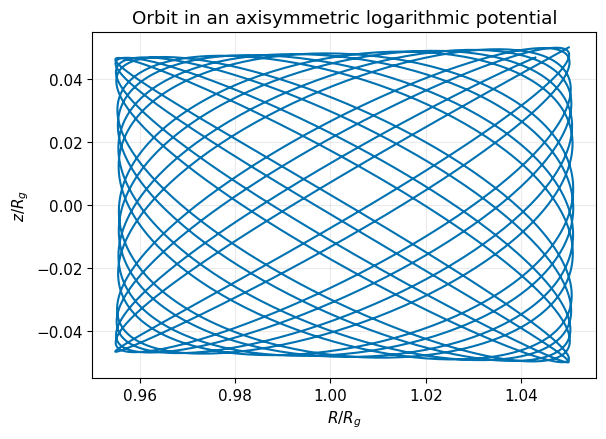

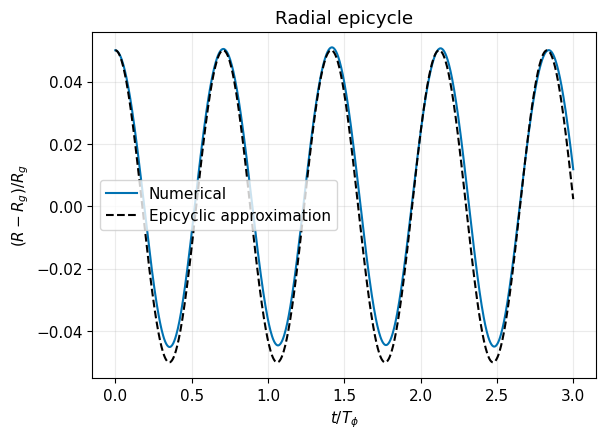

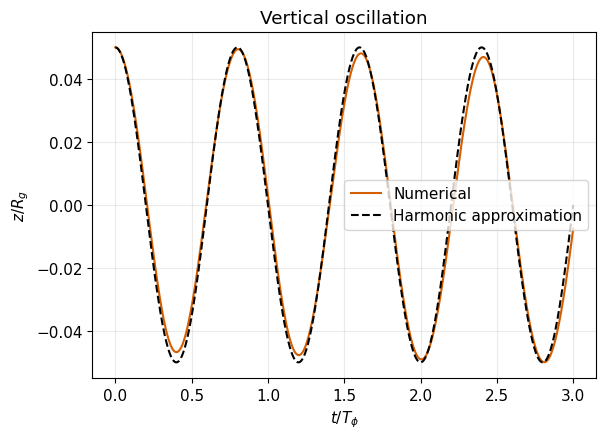

In [6]:
fig, ax = plt.subplots()
ax.plot(R_ax / Rg, x_ax[:, 2] / Rg, color=OI["blue"])
ax.set_xlabel(r"$R/R_g$")
ax.set_ylabel(r"$z/R_g$")
ax.set_title("Orbit in an axisymmetric logarithmic potential")
ax.grid(alpha=0.25)
plt.show()

t_show = t_ax <= 3.0 * Tphi

fig, ax = plt.subplots()
ax.plot(t_ax[t_show] / Tphi, (R_ax[t_show] - Rg) / Rg,
        color=OI["blue"], label="Numerical")
ax.plot(t_ax[t_show] / Tphi, (x_amp / Rg) * np.cos(kappa * t_ax[t_show]),
        "--", color=OI["black"], label="Epicyclic approximation")
ax.set_xlabel(r"$t/T_\phi$")
ax.set_ylabel(r"$(R-R_g)/R_g$")
ax.set_title("Radial epicycle")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
ax.plot(t_ax[t_show] / Tphi, x_ax[t_show, 2] / Rg,
        color=OI["vermillion"], label="Numerical")
ax.plot(t_ax[t_show] / Tphi, (z_amp / Rg) * np.cos(nu_z * t_ax[t_show]),
        "--", color=OI["black"], label="Harmonic approximation")
ax.set_xlabel(r"$t/T_\phi$")
ax.set_ylabel(r"$z/R_g$")
ax.set_title("Vertical oscillation")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


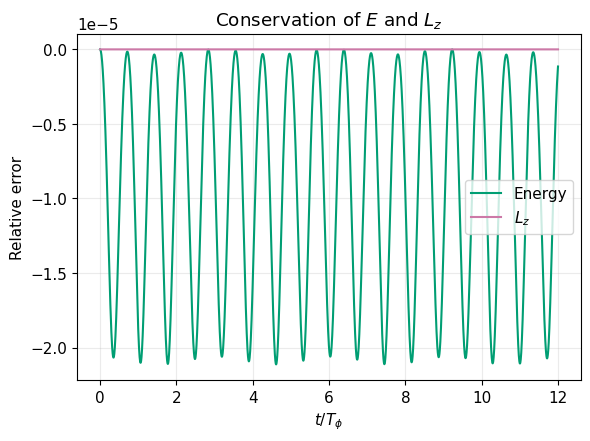

In [7]:
fig, ax = plt.subplots()
ax.plot(t_ax / Tphi, (E_ax - E_ax[0]) / abs(E_ax[0]), color=OI["green"], label="Energy")
ax.plot(t_ax / Tphi, (Lz_ax - Lz_ax[0]) / abs(Lz_ax[0]), color=OI["purple"], label=r"$L_z$")
ax.set_xlabel(r"$t/T_\phi$")
ax.set_ylabel("Relative error")
ax.set_title(r"Conservation of $E$ and $L_z$")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 演習1：軸対称ポテンシャル中の数値軌道の検証

1. $E$と$L_z$の変化を比較してください。$L_z$の変化が丸め誤差程度であっても、位置の誤差が同程度に小さいとは限らない理由を、第3章のキックとドリフトから説明してください。
2. 以下の収束試験で、初期振幅と終端時刻を固定したまま時間刻みを半分ずつにし、数値軌道どうしの差の減り方を調べてください。小振幅近似との差を、この収束次数の測定に使わない理由も説明してください。
3. 次に十分小さい時間刻みを固定して、初期振幅を半分ずつにしてください。差を初期振幅で規格化するのはなぜでしょうか。
4. $q=1$と$q=0.8$について、初期条件を揃えて振動の周期を比較してください。時間刻みを小さくしても残る周期の違いと、時間積分の誤差を区別してください。


## 1.2 時間刻みを変えた収束試験

初期振幅$\xi_0=z_0=0.05R_g$と終端時刻$3T_\phi$を固定し、$\Delta t=T_\phi/300$から刻みを半分ずつにします。小振幅近似ではなく、同じ運動方程式を異なる時間刻みで解いた位置どうしを比較します。
$$
D_{\Delta t}=\max_{t_n}\frac{|\boldsymbol x_{\Delta t}(t_n)-\boldsymbol x_{\Delta t/2}(t_n)|}{R_g},\qquad
p_{\rm self}=\log_2\frac{D_{\Delta t}}{D_{\Delta t/2}}.
$$
比較は両方の計算に共通する時刻に限ります。細かい刻みの配列から`[::2]`で1点おきに取り出すと、粗い配列の時刻に揃います。共通の初期条件・終端時刻を使い、離散化誤差が支配的な範囲では$D_{\Delta t}\propto(\Delta t)^p$となります。$p_{\rm self}$は厳密解なしで求める収束次数の推定値であり、$D_{\Delta t}$自体は厳密解に対する誤差ではありません。

In [8]:
def epicycle_trial(amp_fraction, n_per_period, Rg=1.0, v0=1.0, q=0.8):
    """共通の案内中心と終端時刻3Tphiで、刻み・振幅を変える。"""
    Tphi_trial = 2.0 * np.pi * Rg / v0
    amp = amp_fraction * Rg
    x_init = np.array([Rg + amp, 0.0, amp])
    v_init = np.array([0.0, Rg * v0 / (Rg + amp), 0.0])
    nstep = 3 * int(n_per_period)
    dt = Tphi_trial / n_per_period
    acc = lambda x: acc_log_axisym(x, v0, q)
    x_trial, _ = integrate_leapfrog(acc, x_init, v_init, dt, nstep)
    t_trial = np.arange(nstep + 1) * dt
    return t_trial, x_trial

# 初期振幅を固定し、各時間刻みで独立に積分する。
steps_per_period = np.array([300, 600, 1200, 2400])
trial_orbits = []
for npp in steps_per_period:
    _, x_trial = epicycle_trial(0.05, npp, Rg, vlog, qlog)
    trial_orbits.append(x_trial)

# 共通する出力時刻で位置を引き算し、最大差を求める。
self_diffs = []
for x_coarse, x_fine in zip(trial_orbits[:-1], trial_orbits[1:]):
    dx = x_coarse - x_fine[::2]
    self_diffs.append(np.max(np.linalg.norm(dx, axis=1)) / Rg)
self_diffs = np.asarray(self_diffs)
p_self = np.log2(self_diffs[:-1] / self_diffs[1:])

for npp, d in zip(steps_per_period[:-1], self_diffs):
    print(f"h/Tphi = 1/{npp:4d}, D_h = {d:.6e}")
print("隣り合う刻みでの収束次数 =", np.array2string(p_self, precision=6))

h/Tphi = 1/ 300, D_h = 4.528244e-04
h/Tphi = 1/ 600, D_h = 1.132033e-04
h/Tphi = 1/1200, D_h = 2.830057e-05
隣り合う刻みでの収束次数 = [2.000036 2.000012]


## 1.3 初期振幅を変えた近似解との比較

次に$\Delta t=T_\phi/2400$、終端時刻$3T_\phi$を固定し、共通の振幅比$\alpha=\xi_0/R_g=z_0/R_g$を$0.05,0.025,0.0125$と変えます。各振幅で$L_z=R_gv_0$となる初速度を設定し直します。
$$
A_R=\frac{\max_{t_n}|R(t_n)-R_g-\xi_0\cos(\kappa t_n)|}{|\xi_0|},\qquad
A_z=\frac{\max_{t_n}|z(t_n)-z_0\cos(\nu_z t_n)|}{|z_0|}.
$$
差は初期振幅で規格化します。これにより、振幅を小さくしたため絶対差も小さくなっただけなのか、振幅に比べても一致がよくなったのかを区別します。ここでは振幅を0にしません。

時間積分誤差が十分小さいことを確認するため、同じ比較を$\Delta t=T_\phi/1200$でも行います。両刻みで$A_R,A_z$がほぼ変わらず、振幅を小さくしたときに減るなら、小振幅近似の改善を確かめられます。振幅を極端に小さくすると固定した時間刻みでは不十分になるので、刻みの確認を繰り返してください。

In [9]:
# 振幅を変えた比較を、2つの十分小さい時間刻みで繰り返す。
amp_fractions = np.array([0.05, 0.025, 0.0125])
amp_error_coarse = []
amp_error_fine = []
for amp_fraction in amp_fractions:
    amp = amp_fraction * Rg
    for npp, errors in [(1200, amp_error_coarse), (2400, amp_error_fine)]:
        t_trial, x_trial = epicycle_trial(amp_fraction, npp, Rg, vlog, qlog)
        R_trial = np.sqrt(x_trial[:, 0]**2 + x_trial[:, 1]**2)
        radial_approx = amp * np.cos(kappa * t_trial)
        vertical_approx = amp * np.cos(nu_z * t_trial)
        A_R = np.max(np.abs(R_trial - Rg - radial_approx)) / amp
        A_z = np.max(np.abs(x_trial[:, 2] - vertical_approx)) / amp
        errors.append([A_R, A_z])
amp_error_coarse = np.asarray(amp_error_coarse)
amp_error_fine = np.asarray(amp_error_fine)

print("  alpha       A_R(1200) A_R(2400)   A_z(1200) A_z(2400)")
for alpha, coarse, fine in zip(amp_fractions, amp_error_coarse, amp_error_fine):
    print(f"{alpha:8.4f}      {coarse[0]:.6f}  {fine[0]:.6f}    {coarse[1]:.6f}  {fine[1]:.6f}")

  alpha       A_R(1200) A_R(2400)   A_z(1200) A_z(2400)
  0.0500      0.190613  0.190560    0.150237  0.150217
  0.0250      0.077003  0.076896    0.055322  0.055299
  0.0125      0.033414  0.033206    0.022161  0.022136


# 2. Miyamoto–Nagai軌道

別の軸対称モデルへ、同じ積分器を適用します。
$$
\Phi(R,z)=-\frac{GM}{\sqrt{R^2+(a+\sqrt{z^2+b^2})^2}},\qquad G,M,a,b>0.
$$
$B=\sqrt{z^2+b^2}$、$D=\sqrt{x^2+y^2+(a+B)^2}$と置くと、
$$
g_x=-\frac{GMx}{D^3},\qquad g_y=-\frac{GMy}{D^3},\qquad g_z=-\frac{GM(a+B)z}{BD^3}
$$
です。$g_z$では$B$の$z$依存性も微分します。以下の`acc_mn_cart`がこの式に対応します。

時間に依存しない軸対称系なので、診断に使う保存量は引き続き$E$と$L_z$です。ここでは解析的なポテンシャルと加速度を使い、付録Bの格子上の数値解は入力しません。格子の数値解を使う場合には、補間や数値微分の誤差を別に調べる必要があります。

初期状態と時間は、長さ$a$、速度$v_*=\sqrt{GM/a}$、時間$t_*=a/v_*$で設定します。既定値は$G=M=a=1$、$b=0.25$、$\boldsymbol x_0/a=(3,0,0.5)$、$\boldsymbol v_0/v_*=(0,0.5,0)$、$\Delta t=0.02t_*$、終端時刻$100t_*$です。各出力時刻で保存量を測り、軌道の形だけで計算精度を判断しないでください。


初期エネルギー = -0.17077859
最大 |Delta E/E0|   = 7.330e-07
最大 |Delta Lz/Lz0| = 3.701e-15


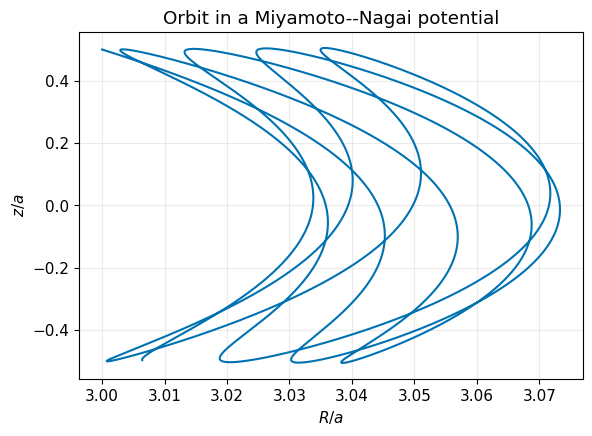

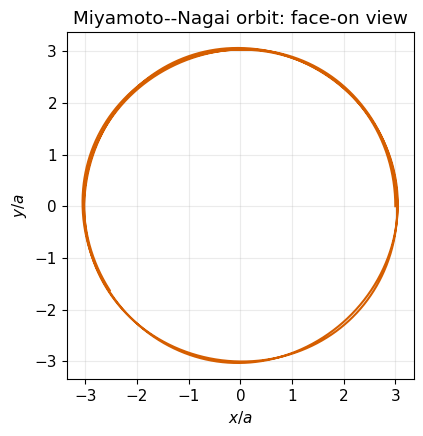

In [10]:
def phi_mn_cart(x, G=1.0, M=1.0, a=1.0, b=0.25):
    R2 = x[..., 0]**2 + x[..., 1]**2
    B = np.sqrt(x[..., 2]**2 + b**2)
    return -G * M / np.sqrt(R2 + (a + B)**2)

def acc_mn_cart(x, G=1.0, M=1.0, a=1.0, b=0.25):
    # BとDの両方のz依存性を含む解析的な加速度。
    X, Y, Z = x
    R2 = X**2 + Y**2
    B = np.sqrt(Z**2 + b**2)
    D = np.sqrt(R2 + (a + B)**2)

    ax = -G * M * X / D**3
    ay = -G * M * Y / D**3
    az = -G * M * (a + B) * Z / (B * D**3)
    return np.array([ax, ay, az])

def energy_mn(x, v, G=1.0, M=1.0, a=1.0, b=0.25):
    return 0.5 * np.sum(v**2, axis=1) + phi_mn_cart(x, G, M, a, b)


# モデルを設定し、長さ・速度・時間の単位を揃える。
M_mn, a_mn, b_mn = 1.0, 1.0, 0.25
vscale_mn = np.sqrt(G * M_mn / a_mn)
tscale_mn = a_mn / vscale_mn
x0_mn = a_mn * np.array([3.0, 0.0, 0.5])
v0_mn = vscale_mn * np.array([0.0, 0.5, 0.0])

# 解析的な加速度で100時間単位まで積分する。
dt_mn = 0.02 * tscale_mn
nstep_mn = int(round(100.0 * tscale_mn / dt_mn))
t_mn = np.arange(nstep_mn + 1) * dt_mn
acc_mn = lambda x: acc_mn_cart(x, G, M_mn, a_mn, b_mn)
x_mn, v_mn = integrate_leapfrog(acc_mn, x0_mn, v0_mn, dt_mn, nstep_mn)

# 位置・速度から半径と保存量を計算する。
E_mn = energy_mn(x_mn, v_mn, G, M_mn, a_mn, b_mn)
Lz_mn = Lz_3d(x_mn, v_mn)
R_mn = np.sqrt(x_mn[:, 0]**2 + x_mn[:, 1]**2)

print(f"初期エネルギー = {E_mn[0]:.8f}")
print(f"最大 |Delta E/E0|   = {np.max(np.abs(E_mn-E_mn[0]))/abs(E_mn[0]):.3e}")
print(f"最大 |Delta Lz/Lz0| = {np.max(np.abs(Lz_mn-Lz_mn[0]))/abs(Lz_mn[0]):.3e}")

fig, ax = plt.subplots()
ax.plot(R_mn / a_mn, x_mn[:, 2] / a_mn, color=OI["blue"])
ax.set_xlabel(r"$R/a$")
ax.set_ylabel(r"$z/a$")
ax.set_title("Orbit in a Miyamoto--Nagai potential")
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
ax.plot(x_mn[:, 0] / a_mn, x_mn[:, 1] / a_mn, color=OI["vermillion"])
ax.set_xlabel(r"$x/a$")
ax.set_ylabel(r"$y/a$")
ax.set_title("Miyamoto--Nagai orbit: face-on view")
ax.set_aspect("equal")
ax.grid(alpha=0.25)
plt.show()


## 発展課題：Miyamoto–Nagai軌道の検証

1. 初期条件と終端時刻を固定して$\Delta t$を半分ずつにし、同じ出力時刻の位置どうしを比較してください。$E$と$L_z$の保存と、位置の収束の確認は別の検証です。
2. 初期の$z$と$v_z$をともに0にした場合に、赤道面に軌道がとどまることを、加速度の式と数値計算の両方で確認してください。
3. $b/a$を小さくしたとき、軌道の変化を調べる前に時間刻みの収束を確かめてください。モデル変更後も同じ時間刻みで十分とは限りません。
4. $G,M,a$と$b/a$を変えたとき、初期条件、速度・時間の単位、加速度関数に渡す値が整合しているか確認してください。
5. Notebook Bの数値重力場を使う場合に必要な補間や数値微分を挙げ、時間積分の誤差と区別して検証する方法を考えてください。この処理は本Notebookには実装していません。


# 3. 非軸対称ポテンシャル

Ryden §7.3の2次元の対数ポテンシャルを使います（式7.68）。
$$
\Phi(x,y)=\frac12v_0^2\ln\left[1+\frac{x^2+y^2/q^2}{r_c^2}\right],\qquad v_0,r_c>0,\quad 0<q\le1.
$$
$D=r_c^2+x^2+y^2/q^2$として、
$$
\boldsymbol a=-\frac{v_0^2}{D}(x,y/q^2),\qquad
\frac{dL_z}{dt}=xg_y-yg_x=\frac{v_0^2xy}{D}(1-q^{-2})
$$
です。$q\ne1$では一般にトルクが0ではなく、$L_z$は保存しません。一方、ポテンシャルは静止しているので、$E$は保存します。$L_z$の変化をすべて数値誤差と解釈しないでください。

中心近傍の$\eta=(x^2+y^2/q^2)/r_c^2\ll1$では$\ln(1+\eta)\simeq\eta$から異方的調和振動子となり、振動数は$\omegg_x=v_0/r_c$、$\omegg_y=v_0/(qr_c)$です。ただし、以下の初期位置では$\eta=4$なので、この近似を軌道全体の基準解には使いません。

Ryden図7.6にならい、$q=\sqrt3/2$、$E=1.5v_0^2$、初期位置$(2r_c,0)$を共通にします。速さは$v_{\rm init}=\sqrt{2[E-\Phi(2r_c,0)]}$、速度方向は$v_y=fv_{\rm init}$、$v_x=+\sqrt{v_{\rm init}^2-v_y^2}$で設定します。ここでは$f=0.5$と$0.9$を使います。初期位置と比エネルギーを同じにし、速度方向だけを変える比較です。

$\Delta t=0.02r_c/v_0$で$300r_c/v_0$まで積分します。この条件で、前者は回り込む向きが変わるbox軌道、後者は中心の周囲を一定の向きに回るloop軌道になります。特定の$f$の値が、別のポテンシャルや初期位置でも同じ軌道の型を与えるという意味ではありません。

図の破線は$\Phi=E$となるゼロ速度境界です。運動エネルギーが非負なので、厳密な軌道は$\Phi\le E$の領域に限られます。ただし、この領域全体を軌道が通るとは限りません。


In [11]:
v0_na = 1.0
rc_na = 1.0
q_na = np.sqrt(3.0) / 2.0
E_target = 1.5 * v0_na**2

def phi_nonaxisym(x, v0=1.0, rc=1.0, q=np.sqrt(3.0)/2.0):
    X, Y = np.asarray(x)[..., 0], np.asarray(x)[..., 1]
    return 0.5 * v0**2 * np.log(1.0 + (X**2 + Y**2/q**2) / rc**2)

def acc_nonaxisym(x, v0=1.0, rc=1.0, q=np.sqrt(3.0)/2.0):
    # 2次元の位置配列から、2成分の加速度を返す。
    X, Y = x
    den = rc**2 + X**2 + Y**2/q**2
    return -v0**2 * np.array([X, Y/q**2]) / den

def energy_nonaxisym(x, v, v0=1.0, rc=1.0, q=np.sqrt(3.0)/2.0):
    return 0.5 * np.sum(v**2, axis=1) + phi_nonaxisym(x, v0, rc, q)


In [12]:
# 初期位置と比エネルギーを共通にして速さを決める。
x_start = np.array([2.0 * rc_na, 0.0])
phi_start = phi_nonaxisym(x_start, v0_na, rc_na, q_na)
if E_target <= phi_start:
    raise ValueError("速度方向を比較するにはE_target > phi_startが必要です。")
speed = np.sqrt(2.0 * (E_target - phi_start))

# このモデルと初期位置でbox・loop軌道になる速度方向を選ぶ。
f_box = 0.50
vy_box = f_box * speed
vx_box = np.sqrt(speed**2 - vy_box**2)
v_box0 = np.array([vx_box, vy_box])
f_loop = 0.90
vy_loop = f_loop * speed
vx_loop = np.sqrt(speed**2 - vy_loop**2)
v_loop0 = np.array([vx_loop, vy_loop])

# 時間の単位をrc/v0に揃え、同じ刻みと終端時刻を使う。
dt_na = 0.02 * rc_na / v0_na
t_end_na = 300.0 * rc_na / v0_na
nstep_na = int(round(t_end_na / dt_na))
t_na = np.arange(nstep_na + 1) * dt_na
acc_na = lambda x: acc_nonaxisym(x, v0_na, rc_na, q_na)
x_box, v_box = integrate_leapfrog(acc_na, x_start, v_box0, dt_na, nstep_na)
x_loop, v_loop = integrate_leapfrog(acc_na, x_start, v_loop0, dt_na, nstep_na)

# Eの変化は保存誤差として、Lzの変化は物理的な変化として調べる。
E_box = energy_nonaxisym(x_box, v_box, v0_na, rc_na, q_na)
E_loop = energy_nonaxisym(x_loop, v_loop, v0_na, rc_na, q_na)
L_box = angular_momentum_z(x_box, v_box)
L_loop = angular_momentum_z(x_loop, v_loop)

print(f"box 軌道の初期エネルギー  = {E_box[0]:.8f}")
print(f"loop 軌道の初期エネルギー = {E_loop[0]:.8f}")
print(f"box 軌道の最大 |Delta E/E0|  = {np.max(np.abs(E_box-E_box[0]))/abs(E_box[0]):.3e}")
print(f"loop 軌道の最大 |Delta E/E0| = {np.max(np.abs(E_loop-E_loop[0]))/abs(E_loop[0]):.3e}")
print(f"box 軌道の Lz/(rc*v0) 範囲  = [{L_box.min()/(rc_na*v0_na):.4f}, {L_box.max()/(rc_na*v0_na):.4f}]")
print(f"loop 軌道の Lz/(rc*v0) 範囲 = [{L_loop.min()/(rc_na*v0_na):.4f}, {L_loop.max()/(rc_na*v0_na):.4f}]")


box 軌道の初期エネルギー  = 1.50000000
loop 軌道の初期エネルギー = 1.50000000
box 軌道の最大 |Delta E/E0|  = 7.769e-05
loop 軌道の最大 |Delta E/E0| = 2.739e-05
box 軌道の Lz/(rc*v0) 範囲  = [-1.2706, 1.2706]
loop 軌道の Lz/(rc*v0) 範囲 = [1.3312, 2.3772]


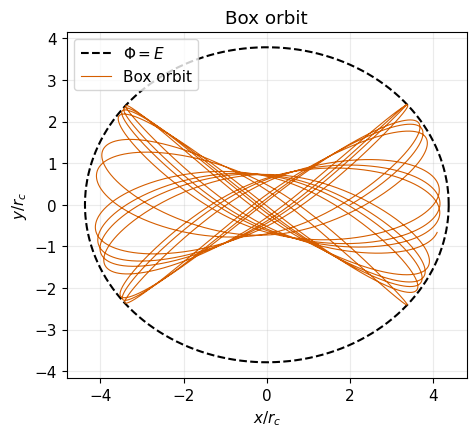

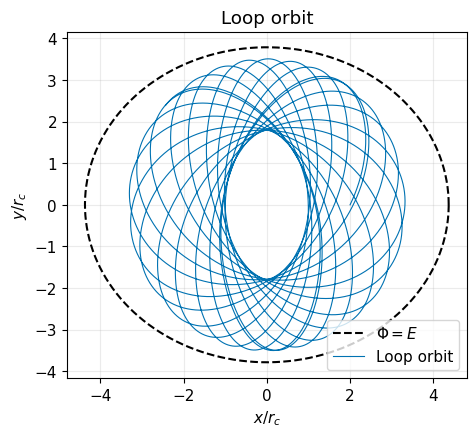

In [13]:
# ゼロ速度境界 Phi(x,y)=E_target
semi_x = rc_na * np.sqrt(np.exp(2.0 * E_target / v0_na**2) - 1.0)
th = np.linspace(0.0, 2.0*np.pi, 500)
xb = semi_x * np.cos(th)
yb = q_na * semi_x * np.sin(th)

fig, ax = plt.subplots()
ax.plot(xb / rc_na, yb / rc_na, "--", color=OI["black"], label=r"$\Phi=E$")
ax.plot(x_box[:, 0] / rc_na, x_box[:, 1] / rc_na, color=OI["vermillion"], lw=0.8, label="Box orbit")
ax.set_xlabel(r"$x/r_c$")
ax.set_ylabel(r"$y/r_c$")
ax.set_title("Box orbit")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
ax.plot(xb / rc_na, yb / rc_na, "--", color=OI["black"], label=r"$\Phi=E$")
ax.plot(x_loop[:, 0] / rc_na, x_loop[:, 1] / rc_na, color=OI["blue"], lw=0.8, label="Loop orbit")
ax.set_xlabel(r"$x/r_c$")
ax.set_ylabel(r"$y/r_c$")
ax.set_title("Loop orbit")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


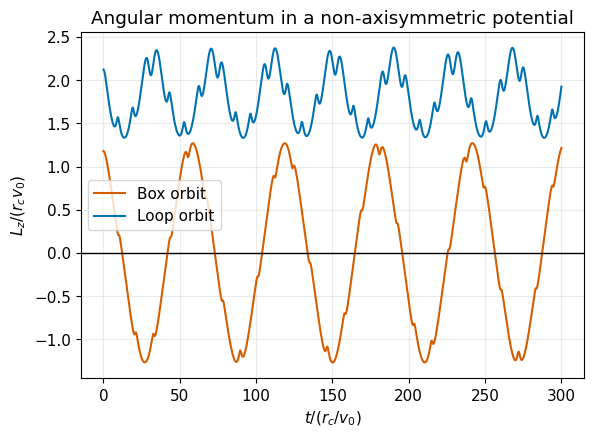

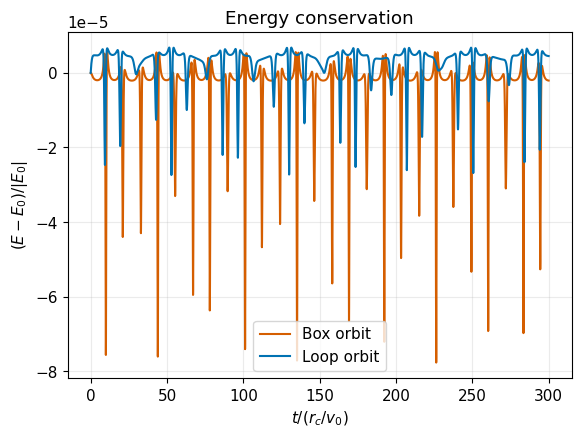

In [14]:
fig, ax = plt.subplots()
ax.plot(t_na / (rc_na / v0_na), L_box / (rc_na * v0_na), color=OI["vermillion"], label="Box orbit")
ax.plot(t_na / (rc_na / v0_na), L_loop / (rc_na * v0_na), color=OI["blue"], label="Loop orbit")
ax.axhline(0.0, color=OI["black"], lw=1)
ax.set_xlabel(r"$t/(r_c/v_0)$")
ax.set_ylabel(r"$L_z/(r_c v_0)$")
ax.set_title("Angular momentum in a non-axisymmetric potential")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
ax.plot(t_na / (rc_na / v0_na), (E_box-E_box[0])/abs(E_box[0]), color=OI["vermillion"], label="Box orbit")
ax.plot(t_na / (rc_na / v0_na), (E_loop-E_loop[0])/abs(E_loop[0]), color=OI["blue"], label="Loop orbit")
ax.set_xlabel(r"$t/(r_c/v_0)$")
ax.set_ylabel(r"$(E-E_0)/|E_0|$")
ax.set_title("Energy conservation")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 演習2：box軌道とloop軌道の診断

1. $E$の最大絶対相対変化、$L_z$の変化範囲と符号を調べてください。どれを保存誤差として扱えますか。
2. 同じ初期条件・終端時刻で$\Delta t$を半分にし、エネルギー誤差が減ることと、$L_z$の物理的な変化が残ることを確かめてください。位置の比較は同じ時刻の出力点で行います。
3. $q=1$では解析的なトルクが0になります。数値計算でも$L_z$が丸め誤差の範囲で保たれるか確認してください。$q$を変えるたびに、同じ目標エネルギーから初速度を設定し直します。
4. 速度方向$f$を変え、初期エネルギーが揃っていることを確かめてから軌道を比較してください。保存量だけで軌道の形や位置を決められないことを確認します。
5. 積分時間と時間刻みを別々に変え、出力点で測った最小半径を比較してください。この最小値が連続な軌道の最小半径と同じとは限らず、無限時間で中心へ任意に近づくことの証明にもなりません。


# まとめ

数値積分器と加速度関数を分けることで、同じKDK形式のリープフロッグ法を異なる重力場へ適用できます。ただし、加速度、初期条件、診断量、時間刻みの妥当性はモデルごとに確かめ直します。

数値軌道どうしの収束と小振幅近似との一致は、異なる検証です。時間刻みを小さくしても残る差を調べるには、初期振幅も別に変える必要があります。近似解との差をすべて時間積分の誤差として扱ってはいけません。

保存量は対称性に応じて選びます。ここで扱った静止した重力場では$E$が保存します。軸対称系では$L_z$も保存しますが、非軸対称系では一般に変化します。保存量がよく保たれることだけでは、各時刻の位置の精度は保証されません。また、有限時間の出力から判断できる範囲を越えて、軌道の長時間の性質を断定しないことが重要です。
